# Budget-forcing evaluation (adapter only)

This notebook loads a previously trained QLoRA adapter and evaluates all test records at 0 and 2 forced continuations. It does not train.

**Upload required:** `test.json`, `adapter_config.json`, and `adapter_model.safetensors`. Upload the adapter files directly to `/content` or upload the complete `sft_qlora/` adapter folder. The notebook downloads the public base model automatically if it is not cached. The fresh adapter must be downloaded from the training run; do not substitute one from an older experiment.


## 1. Install inference dependencies

Install model loading, quantization, adapter, progress, and plotting libraries.


In [1]:
!pip -q install -U transformers accelerate bitsandbytes peft matplotlib tqdm huggingface_hub


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 6.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.4/57.4 kB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 105.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 20.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 116.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.2/80.2 kB 8.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 839.9/839.9 kB 62.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
datasets 4.8.5 requires huggingface-hub<2.0,>=0.25.0, but you have huggingface-hub 2.2.0 which is incompatible.
diffusers 0.41.0 requires huggingface-hub<2.0,>=1.32.0, but you have huggingface-hub 2.2.0 which is incompatible.


## 2. Find the test split and adapter; check the GPU

This cell supports a flat upload or the package's `budget_forcing/` folder and prints the number of test examples.


In [2]:
import json, re, time
from decimal import Decimal, InvalidOperation
from pathlib import Path
import matplotlib.pyplot as plt
import torch
from tqdm.auto import tqdm
from huggingface_hub import snapshot_download
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
from peft import PeftModel

ROOT = Path('/content')
PACKAGE_DIR = ROOT / 'budget_forcing'
PACKAGE_LAYOUT_DIR = ROOT / 'budget-force-reasoning' / 'budget_forcing'
MODEL_ID = 'deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B'
BASE_MODEL_DIR = ROOT / 'base_model_weights'
assert torch.cuda.is_available(), 'Select a GPU runtime before continuing.'
print('GPU:', torch.cuda.get_device_name(0))

def find_test():
    for path in (ROOT/'test.json', PACKAGE_DIR/'test.json', PACKAGE_LAYOUT_DIR/'test.json', Path.cwd()/'test.json'):
        if path.is_file(): return path
    raise FileNotFoundError('Upload only test.json to /content or /content/budget_forcing.')

def find_adapter():
    candidates = [ROOT, ROOT/'sft_qlora', PACKAGE_DIR, PACKAGE_LAYOUT_DIR]
    for path in candidates:
        if (path/'adapter_config.json').is_file() and (path/'adapter_model.safetensors').is_file():
            return path
    raise FileNotFoundError('Upload adapter_config.json and adapter_model.safetensors from the trained run to /content (or upload the sft_qlora folder).')

TEST_PATH = find_test()
ADAPTER_DIR = find_adapter()
test_rows = json.loads(TEST_PATH.read_text(encoding='utf-8'))
required = {'id','x_i','y_i','topic'}
assert test_rows and all(required.issubset(row) for row in test_rows), 'test.json does not match the expected final schema.'
assert len({row['id'] for row in test_rows}) == len(test_rows), 'Duplicate test IDs found.'
print('Test examples:', len(test_rows), '| adapter directory:', ADAPTER_DIR)

BASE_MODEL_DIR.mkdir(parents=True, exist_ok=True)
if not (BASE_MODEL_DIR/'config.json').is_file():
    print('Downloading public base model. ETA: around 5-15 minutes, depending on network speed.')
    snapshot_download(repo_id=MODEL_ID, local_dir=BASE_MODEL_DIR)
else:
    print('Base model already cached; download ETA: 0 minutes.')

tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL_DIR, local_files_only=True)
tokenizer.pad_token = tokenizer.pad_token or tokenizer.eos_token
tokenizer.padding_side = 'left'
quantization = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type='nf4', bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=torch.float16)
base_model = AutoModelForCausalLM.from_pretrained(BASE_MODEL_DIR, local_files_only=True, quantization_config=quantization, device_map='auto')
model = PeftModel.from_pretrained(base_model, ADAPTER_DIR, is_trainable=False)
model.eval()
print('Trained adapter loaded. No training will be run in this notebook.')


GPU: Tesla T4
Test examples: 90 | adapter directory: /content


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

Trained adapter loaded. No training will be run in this notebook.


## 3. Set generation limits and define budget-forcing helpers

The reasoning cap is shared across all continuations. A `Wait` is appended only after an attempted `<final>` or EOS; the model's `</think>` alone does not trigger forcing.


In [3]:
model.config.use_cache = True; model.eval()
BATCH_SIZE = 16
SEGMENT_TOKENS = 1024      # Per-call ceiling; the actual call uses only the remaining total budget.
ANSWER_TOKENS = 32         # Separate allowance for the final numeric answer.
THINKING_BUDGET = 1024     # Shared maximum model-produced reasoning tokens per example.
def canonical(value):
    try:
        number = Decimal(str(value).strip().replace(',', '').replace('$', ''))
    except InvalidOperation:
        return None
    if not number.is_finite():
        return None
    text = format(number.normalize(), 'f')
    if '.' in text:
        text = text.rstrip('0').rstrip('.')
    return '0' if text in ('', '-0') else text

def batch_generate(prompts, max_tokens, stop_on_reasoning_end=False):
    encoded = tokenizer(prompts, return_tensors='pt', padding=True, truncation=True, max_length=3072).to(model.device)
    generation_options = dict(do_sample=False, max_new_tokens=max_tokens, pad_token_id=tokenizer.eos_token_id, eos_token_id=tokenizer.eos_token_id)
    if stop_on_reasoning_end:
        # Do not stop on </think> alone. Force only when the model attempts its final answer.
        generation_options.update(stop_strings=['<final>'], tokenizer=tokenizer)
    with torch.inference_mode():
        output = model.generate(**encoded, **generation_options)
    prompt_width = encoded['input_ids'].shape[1]
    eos_ids = {tokenizer.eos_token_id} if isinstance(tokenizer.eos_token_id, int) else set(tokenizer.eos_token_id or [])
    generated = []
    for i in range(len(prompts)):
        token_ids = output[i, prompt_width:].tolist()
        text = tokenizer.decode(token_ids, skip_special_tokens=True)
        marker_stop = '<final>' in text
        eos_stop = any(token_id in eos_ids for token_id in token_ids)
        generated.append({'text': text, 'naturally_stopped': marker_stop or eos_stop})
    return generated

def split_at_reasoning_stop(text):
    # Intercept <final>, then remove an immediately preceding </think> from the retained prefix.
    final_position = text.find('<final>')
    if final_position >= 0:
        reasoning = text[:final_position].rstrip()
        reasoning = re.sub(r'\s*</think>\s*$', '', reasoning).rstrip()
        return reasoning, True
    return text.rstrip(), False

def evaluate_configuration(num_ignore):
    results = []
    for start in tqdm(range(0, len(test_rows), BATCH_SIZE), desc=f'ignore={num_ignore}'):
        batch = test_rows[start:start + BATCH_SIZE]
        prefixes = [f"Question: {row['x_i']}\n\n<think>\n" for row in batch]
        thinking = [''] * len(batch)
        counts = [0] * len(batch)
        forced = [0] * len(batch)
        completed = [False] * len(batch)

        # Only unfinished examples remain active. This is both faster and faithful to budget forcing.
        active = list(range(len(batch)))
        while active:
            prompts = [prefixes[i] + thinking[i] for i in active]
            chunk_limit = min(SEGMENT_TOKENS, max(THINKING_BUDGET - counts[i] for i in active))
            segments = batch_generate(prompts, chunk_limit, stop_on_reasoning_end=True)
            still_active = []
            for i, generated in zip(active, segments):
                segment, marker_stop = split_at_reasoning_stop(generated['text'])
                reached_stop = marker_stop or generated['naturally_stopped']
                segment_ids = tokenizer.encode(segment, add_special_tokens=False)
                remaining = THINKING_BUDGET - counts[i]
                truncated_by_budget = len(segment_ids) > remaining
                if truncated_by_budget:
                    segment_ids = segment_ids[:remaining]
                    segment = tokenizer.decode(segment_ids, skip_special_tokens=True)
                    # A final/EOS beyond the allowed budget is not a valid in-budget stop.
                    reached_stop = False
                thinking[i] += segment
                counts[i] += len(segment_ids)
                if reached_stop:
                    # EOS may follow </think> without <final>; keep tags out of the continued reasoning prefix.
                    thinking[i] = re.sub(r'\s*</think>\s*$', '', thinking[i]).rstrip()

                if not segment_ids and not reached_stop:
                    # An immediate EOS without a closing tag is malformed; do not loop forever.
                    continue
                if reached_stop and forced[i] < num_ignore and counts[i] < THINKING_BUDGET:
                    thinking[i] += '\nWait\n'
                    forced[i] += 1
                    still_active.append(i)
                elif reached_stop:
                    completed[i] = True
                elif counts[i] < THINKING_BUDGET:
                    still_active.append(i)
            active = still_active

        answer_prompts = [prefixes[i] + thinking[i] + '\n</think>\n<final>\n' for i in range(len(batch))]
        answers = [item['text'] for item in batch_generate(answer_prompts, ANSWER_TOKENS)]
        for i, (row, answer) in enumerate(zip(batch, answers)):
            numbers = re.findall(r'(?<![\w.])-?\$?[\d,]+(?:\.\d+)?', answer)
            prediction = canonical(numbers[-1]) if numbers else None
            malformed = prediction is None or '</think>' in thinking[i] or '<final>' in thinking[i]
            error_flags = {
                'missing_answer': prediction is None,
                'incomplete_forcing': forced[i] != num_ignore,
                'thinking_budget_exhausted': counts[i] >= THINKING_BUDGET and not completed[i],
                'malformed_reasoning': '</think>' in thinking[i] or '<final>' in thinking[i],
            }
            control = counts[i] <= THINKING_BUDGET and completed[i] and forced[i] == num_ignore and not malformed
            results.append({
                'id': row['id'], 'topic': row['topic'], 'expected_answer': canonical(row['y_i']),
                'extracted_answer': prediction, 'correct': prediction == canonical(row['y_i']),
                'thinking_tokens': counts[i], 'forced_continuations': forced[i],
                'requested_continuations': num_ignore, 'control': control, 'error_flags': error_flags,
                'trace': '<think>\n' + thinking[i] + '\n</think>\n<final>\n' + answer,
            })
    return results


## 4. Evaluate every test row at 0 and 2 continuations

Greedy decoding is used. Progress bars show live ETAs, and partial JSON is saved after each configuration.


In [4]:
predictions={}; summary={}; evaluation_started=time.time()
evaluation_estimates={0:'15-25 minutes',2:'30-55 minutes'}
for ignored in (0,2):
    print(f'Starting ignore={ignored}. Typical T4 ETA: {evaluation_estimates[ignored]}. The progress bar shows the live ETA.')
    rows=evaluate_configuration(ignored); predictions[str(ignored)]=rows
    summary[str(ignored)]={'accuracy':sum(x['correct'] for x in rows)/len(rows),'correct':sum(x['correct'] for x in rows),'total':len(rows),'control':sum(x['control'] for x in rows)/len(rows),'average_thinking_tokens':sum(x['thinking_tokens'] for x in rows)/len(rows)}
    (ROOT/'sft_budget_results.partial.json').write_text(json.dumps({'summary':summary,'predictions':predictions},indent=2),encoding='utf-8')
print('Evaluation minutes:',(time.time()-evaluation_started)/60)


Starting ignore=0. Typical T4 ETA: 15-25 minutes. The progress bar shows the live ETA.


ignore=0:   0%|          | 0/6 [00:00<?, ?it/s]

Starting ignore=2. Typical T4 ETA: 30-55 minutes. The progress bar shows the live ETA.


ignore=2:   0%|          | 0/6 [00:00<?, ?it/s]

Evaluation minutes: 41.762861824035646


## 5. Compare accuracy, control, scaling, and topic results

This cell saves all evaluation plots and the complete traces in JSON under `/content`.


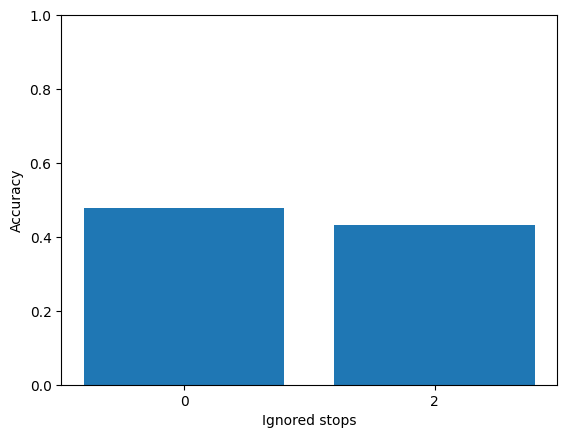

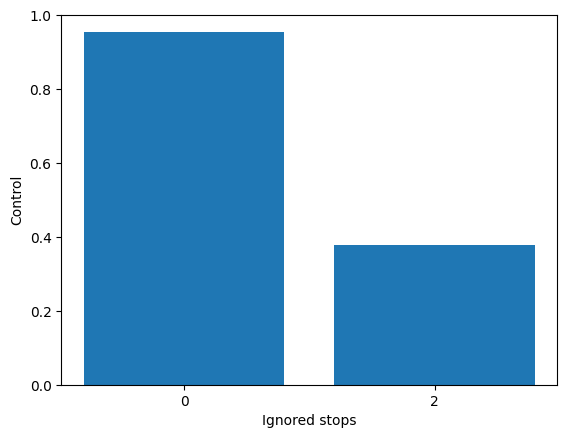

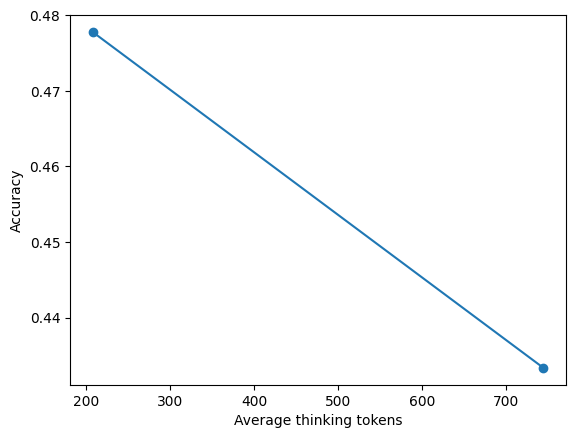

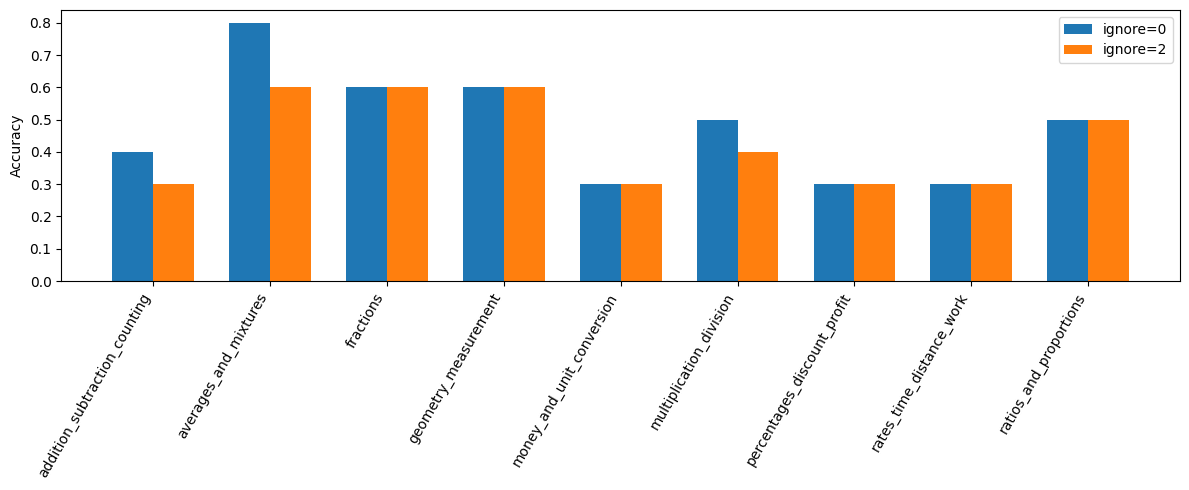

{
  "0": {
    "accuracy": 0.4777777777777778,
    "correct": 43,
    "total": 90,
    "control": 0.9555555555555556,
    "average_thinking_tokens": 207.6888888888889
  },
  "2": {
    "accuracy": 0.43333333333333335,
    "correct": 39,
    "total": 90,
    "control": 0.37777777777777777,
    "average_thinking_tokens": 744.5888888888888
  },
  "scaling_slope": -8.277974379669297e-05,
  "accuracy_gain_2_vs_0": -0.04444444444444445,
  "two_cycle_improved": false
}


In [5]:
configs=['0','2']; tokens=[summary[c]['average_thinking_tokens'] for c in configs]; accuracies=[summary[c]['accuracy'] for c in configs]
summary['scaling_slope']=(accuracies[-1]-accuracies[0])/(tokens[-1]-tokens[0]) if tokens[-1]!=tokens[0] else None
summary['accuracy_gain_2_vs_0']=summary['2']['accuracy']-summary['0']['accuracy']
summary['two_cycle_improved']=summary['accuracy_gain_2_vs_0']>0
topics=sorted({r['topic'] for r in test_rows}); per_topic={}
for c in configs: per_topic[c]={t:sum(x['correct'] for x in predictions[c] if x['topic']==t)/sum(1 for x in predictions[c] if x['topic']==t) for t in topics}
for name,values,ylabel in [('accuracy_comparison',[summary[c]['accuracy'] for c in configs],'Accuracy'),('control_comparison',[summary[c]['control'] for c in configs],'Control')]:
    plt.figure(); plt.bar(configs,values); plt.xlabel('Ignored stops'); plt.ylabel(ylabel); plt.ylim(0,1); plt.savefig(ROOT/f'{name}.png',dpi=160,bbox_inches='tight'); plt.show()
plt.figure(); plt.plot(tokens,accuracies,'o-'); plt.xlabel('Average thinking tokens'); plt.ylabel('Accuracy'); plt.savefig(ROOT/'scaling_comparison.png',dpi=160,bbox_inches='tight'); plt.show()
plt.figure(figsize=(12,5)); width=.35; xs=range(len(topics))
for j,c in enumerate(configs): plt.bar([x+(j-(len(configs)-1)/2)*width for x in xs],[per_topic[c][t] for t in topics],width,label=f'ignore={c}')
plt.xticks(list(xs),topics,rotation=60,ha='right'); plt.ylabel('Accuracy'); plt.legend(); plt.tight_layout(); plt.savefig(ROOT/'per_topic_accuracy.png',dpi=160); plt.show()
results={'model':MODEL_ID,'method':'QLoRA','summary':summary,'per_topic_accuracy':per_topic,'predictions':predictions}
(ROOT/'sft_budget_results.json').write_text(json.dumps(results,ensure_ascii=False,indent=2)+'\n',encoding='utf-8'); print(json.dumps(summary,indent=2))
